In [3]:
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn

# Печатаем версии среды и основных библиотек одним блоком.
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.3
Pandas: 3.0.6
Matplotlib: 3.11.2
scikit-learn: 1.9.1


In [6]:
X = np.array([[1, 1], [1, 2], [2, 2], [2, 3]])
y = np.dot(X, np.array([1, 2])) + 3

print(X)
print(y)

[[1 1]
 [1 2]
 [2 2]
 [2 3]]
[ 6  8  9 11]


In [2]:
# Скрываем только предупреждения о будущих изменениях API;
# остальные предупреждения оставляем видимыми.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Базовые библиотеки для вычислений, таблиц и графиков.
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Компоненты scikit-learn сгруппированы по назначению.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Все случайные операции используют одно значение для воспроизводимости.
RANDOM_STATE = 42            # только для учебного примера
TEST_SIZE = 0.20
SCORING = "f1_macro"


Источник: локальная копия ML_Lab1_Datasets\example_titanic_40945.csv
Размер X: (1309, 7)
Классы: [np.int64(0), np.int64(1)]


,pclass,sex,age,sibsp,parch,fare,embarked
0,1,female,29.0000,0,0,211.3375,S
1,1,male,0.9167,1,2,151.5500,S
2,1,female,2.0000,1,2,151.5500,S
3,1,male,30.0000,1,2,151.5500,S
4,1,female,25.0000,1,2,151.5500,S


,dtype,n_unique,n_missing,missing_share
pclass,int64,3,0,0.000
sex,str,2,0,0.000
age,float64,98,263,0.201
sibsp,int64,7,0,0.000
parch,int64,8,0,0.000
fare,float64,281,1,0.001
embarked,str,3,2,0.002


,count,share
survived,,
0,809,0.618
1,500,0.382


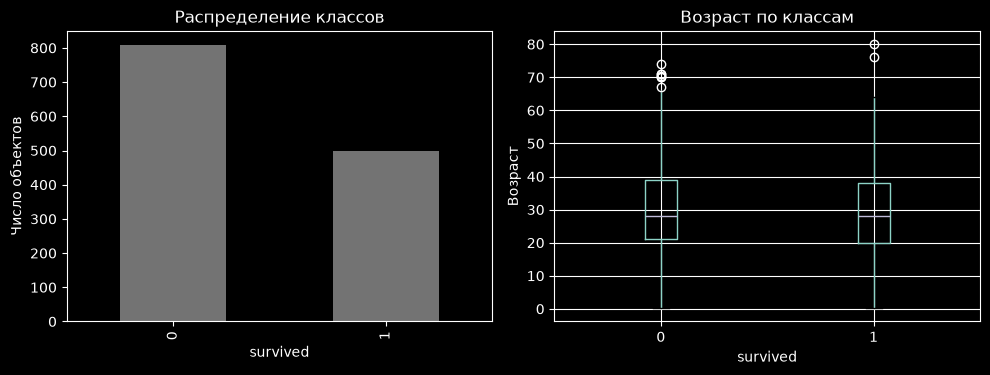

In [3]:
from IPython.display import display

# Сначала пытаемся использовать приложенную локальную копию.
example_path = Path("ML_Lab1_Datasets") / "example_titanic_40945.csv"

if example_path.exists():
    frame = pd.read_csv(example_path)
    print("Источник: локальная копия", example_path)
else:
    # Резервный вариант нужен, если архив с данными не был распакован.
    data = fetch_openml(data_id=40945, as_frame=True)
    frame = data.data.copy()
    frame["survived"] = data.target
    print("Источник: OpenML, data_id 40945")

# Для учебного примера оставляем семь содержательных признаков разных типов.
features = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked",
]
X = frame[features].copy()
y = pd.to_numeric(frame["survived"]).astype("int64")

# Проверяем размерность, классы и первые строки до дальнейшей обработки.
print("Размер X:", X.shape)
print("Классы:", sorted(y.unique()))
display(X.head())

# Карточка признаков объединяет тип, число значений и статистику пропусков.
data_card = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "n_unique": X.nunique(dropna=True),
    "n_missing": X.isna().sum(),
    "missing_share": X.isna().mean().round(3),
})

# Отдельно оцениваем абсолютный и относительный размер каждого класса.
class_table = pd.DataFrame({
    "count": y.value_counts().sort_index(),
    "share": y.value_counts(normalize=True).sort_index().round(3),
})

# display удобнее print для просмотра таблиц внутри Jupyter Notebook.
display(data_card)
display(class_table)

# На одном рисунке показываем баланс классов и распределение возраста.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Столбчатая диаграмма позволяет быстро увидеть дисбаланс классов.
y.value_counts().sort_index().plot.bar(ax=axes[0], color="0.45")
axes[0].set_title("Распределение классов")
axes[0].set_xlabel("survived")
axes[0].set_ylabel("Число объектов")

plot_frame = pd.DataFrame({"age": X["age"], "survived": y})
# Boxplot показывает медиану, разброс и возможные выбросы по каждому классу.
plot_frame.boxplot(column="age", by="survived", ax=axes[1])
axes[1].set_title("Возраст по классам")
axes[1].set_xlabel("survived")
axes[1].set_ylabel("Возраст")

# Pandas добавляет общий заголовок автоматически — убираем его перед выводом.
plt.suptitle("")
plt.tight_layout()
plt.show()


In [4]:
#Далее идёт уже ML
## 5. Разбиение данных

In [5]:
# Тестовая выборка отделяется один раз и остаётся закрытой до финальной оценки.
# stratify сохраняет приблизительные доли классов в обеих частях.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

# Кросс-валидация применяется только внутри обучающей части.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("CV:", cv)

# Размерности помогают проверить, что разбиение выполнено ожидаемым образом.
print("Train:", X_train.shape)
print("Test:", X_test.shape)




CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Train: (1047, 7)
Test: (262, 7)


In [7]:
## 6. Базовая модель
# most_frequent всегда предсказывает самый частый класс и не использует признаки.
baseline = DummyClassifier(strategy="most_frequent")

# Используем ту же CV-схему, что и для основных моделей.
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
)

print(baseline_cv)

# Усредняем метрики по пяти фолдам для компактного сравнения.
baseline_summary = pd.Series({
    "accuracy_cv_mean": baseline_cv["test_accuracy"].mean(),
    "f1_macro_cv_mean": baseline_cv["test_f1_macro"].mean(),
})
display(baseline_summary.round(4))

{'fit_time': array([0.0009613 , 0.00073743, 0.00102472, 0.00088358, 0.00069952]), 'score_time': array([0.0032804 , 0.00354242, 0.00466514, 0.0029583 , 0.00298238]), 'test_accuracy': array([0.61904762, 0.61904762, 0.61722488, 0.61722488, 0.61722488]), 'test_f1_macro': array([0.38235294, 0.38235294, 0.3816568 , 0.3816568 , 0.3816568 ])}


accuracy_cv_mean    0.6180
f1_macro_cv_mean    0.3819
dtype: float64

In [9]:
## 7. Подготовка данных для ручной реализации SGD

manual_features = ["age", "fare", "sibsp", "parch"]

X_demo_train, X_demo_val, y_demo_train, y_demo_val = train_test_split(
    X_train[manual_features],
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_demo_train = imputer.fit_transform(X_demo_train)
X_demo_val = imputer.transform(X_demo_val)

X_demo_train = scaler.fit_transform(X_demo_train)
X_demo_val = scaler.transform(X_demo_val)

y_demo_train_pm = np.where(y_demo_train.to_numpy() == 1, 1.0, -1.0)
y_demo_val_pm = np.where(y_demo_val.to_numpy() == 1, 1.0, -1.0)

In [11]:
## 8. Функции потерь и обучения

def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z))


def mean_logistic_loss(X, y_pm, w, b):
    margins = y_pm * (X @ w + b)
    return np.mean(np.logaddexp(0.0, -margins))


def train_logreg_sgd(
    X_train, y_train_pm, X_val, y_val_pm, *,
    eta=0.01, tau=1e-4, epochs=50, random_state=42,
):
    rng = np.random.default_rng(random_state)
    w = np.zeros(X_train.shape[1], dtype=float)
    b = 0.0
    history = {"train_loss": [], "val_loss": [], "weight_norm": []}

    for _ in range(epochs):
        for i in rng.permutation(len(X_train)):
            x_i = X_train[i]
            y_i = y_train_pm[i]
            margin = y_i * (x_i @ w + b)

            factor = -y_i * sigmoid(-margin)
            grad_w = factor * x_i + tau * w
            grad_b = factor

            w -= eta * grad_w
            b -= eta * grad_b

        history["train_loss"].append(mean_logistic_loss(X_train, y_train_pm, w, b))
        history["val_loss"].append(mean_logistic_loss(X_val, y_val_pm, w, b))
        history["weight_norm"].append(np.linalg.norm(w))

    return w, b, pd.DataFrame(history)

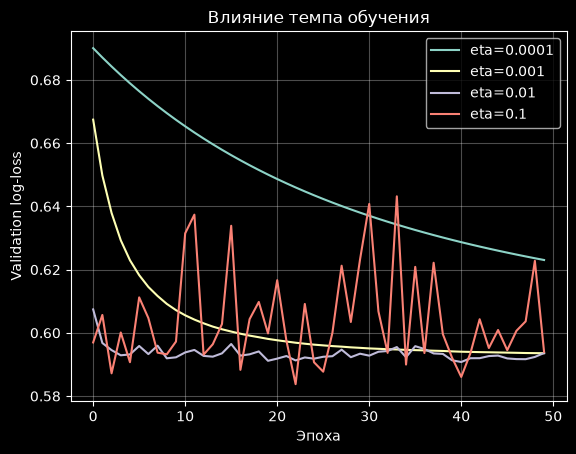

,final_train_loss,final_val_loss,weight_norm
0.0001,0.6400,0.6230,0.3340
0.0010,0.6258,0.5936,0.7560
0.0100,0.6263,0.5936,0.7370
0.1000,0.6314,0.5940,0.8728


In [12]:
## 9. Исследование темпа обучения
eta_values = [0.0001, 0.001, 0.01, 0.1]
eta_runs = {}

for eta in eta_values:
    _, _, history = train_logreg_sgd(
        X_demo_train, y_demo_train_pm,
        X_demo_val, y_demo_val_pm,
        eta=eta, tau=1e-4, epochs=50,
        random_state=RANDOM_STATE,
    )
    eta_runs[eta] = history
    plt.plot(history["val_loss"], label=f"eta={eta}")

plt.xlabel("Эпоха")
plt.ylabel("Validation log-loss")
plt.title("Влияние темпа обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

eta_result = pd.DataFrame({
    eta: {
        "final_train_loss": h["train_loss"].iloc[-1],
        "final_val_loss": h["val_loss"].iloc[-1],
        "weight_norm": h["weight_norm"].iloc[-1],
    }
    for eta, h in eta_runs.items()
}).T
display(eta_result.round(4))

In [13]:
## 10. Исследование регуляризации
best_eta = eta_result["final_val_loss"].idxmin()
tau_values = [0.0, 1e-4, 1e-2]
tau_result = []

for tau in tau_values:
    w_sgd, b_sgd, history = train_logreg_sgd(
        X_demo_train, y_demo_train_pm,
        X_demo_val, y_demo_val_pm,
        eta=float(best_eta), tau=tau, epochs=50,
        random_state=RANDOM_STATE,
    )
    tau_result.append({
        "tau": tau,
        "val_loss": history["val_loss"].iloc[-1],
        "weight_norm": np.linalg.norm(w_sgd),
    })

tau_result = pd.DataFrame(tau_result)
display(tau_result.round(4))

,tau,val_loss,weight_norm
0,0.0000,0.5935,0.7568
1,0.0001,0.5936,0.7560
2,0.0100,0.5963,0.6901


In [14]:
## 11. Полный preprocessing pipeline
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

sgd_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", SGDClassifier(
        loss="log_loss",
        penalty="l2",
        learning_rate="constant",
        max_iter=2000,
        tol=1e-4,
        random_state=RANDOM_STATE,
    )),
])

In [15]:
## 12. Подбор гиперпараметров SGD
sgd_param_grid = {
    "model__eta0": [0.001, 0.01, 0.1],
    "model__alpha": [1e-6, 1e-4, 1e-2],
}

sgd_search = GridSearchCV(
    estimator=sgd_pipeline,
    param_grid=sgd_param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
sgd_search.fit(X_train, y_train)

print("Лучшие параметры SGD:", sgd_search.best_params_)
print("Лучший CV macro-F1:", round(sgd_search.best_score_, 4))

sgd_cv_table = pd.DataFrame(sgd_search.cv_results_)[[
    "param_model__eta0",
    "param_model__alpha",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values("rank_test_score")
display(sgd_cv_table.round(4))

Лучшие параметры SGD: {'model__alpha': 1e-06, 'model__eta0': 0.01}
Лучший CV macro-F1: 0.7692


,param_model__eta0,param_model__alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,0.010,0.0000,0.7661,0.7692,0.0143,1
4,0.010,0.0001,0.7661,0.7692,0.0143,1
6,0.001,0.0100,0.7681,0.7659,0.0114,3
0,0.001,0.0000,0.7665,0.7649,0.0136,4
3,0.001,0.0001,0.7668,0.7649,0.0136,4
7,0.010,0.0100,0.7684,0.7614,0.0124,6
2,0.100,0.0000,0.7604,0.7482,0.0164,7
5,0.100,0.0001,0.7606,0.7482,0.0164,7
8,0.100,0.0100,0.7565,0.7457,0.0193,9


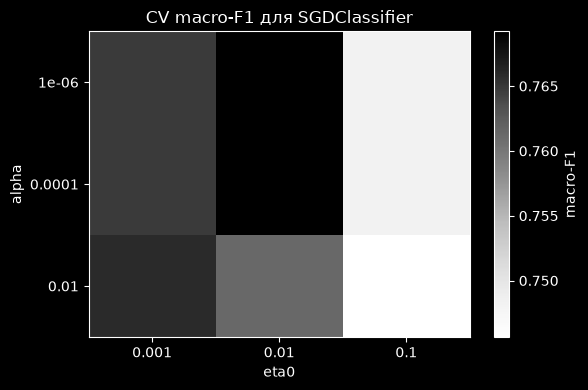

In [16]:
## 13. Тепловая карта CV
pivot = sgd_cv_table.pivot_table(
    index="param_model__alpha",
    columns="param_model__eta0",
    values="mean_test_score",
)

fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(pivot.to_numpy(), cmap="Greys", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), labels=pivot.columns)
ax.set_yticks(range(len(pivot.index)), labels=pivot.index)
ax.set_xlabel("eta0")
ax.set_ylabel("alpha")
ax.set_title("CV macro-F1 для SGDClassifier")
fig.colorbar(image, ax=ax, label="macro-F1")
plt.tight_layout()
plt.show()

In [17]:
## 14. Подбор C для LogisticRegression
logreg_pipeline = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE,
    )),
])

logreg_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0]},
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
)
logreg_search.fit(X_train, y_train)

cv_comparison = pd.DataFrame([
    {
        "model": "DummyClassifier",
        "best_params": "strategy=most_frequent",
        "cv_macro_f1": baseline_summary["f1_macro_cv_mean"],
    },
    {
        "model": "SGDClassifier",
        "best_params": str(sgd_search.best_params_),
        "cv_macro_f1": sgd_search.best_score_,
    },
    {
        "model": "LogisticRegression",
        "best_params": str(logreg_search.best_params_),
        "cv_macro_f1": logreg_search.best_score_,
    },
]).sort_values("cv_macro_f1", ascending=False)

display(cv_comparison.round(4))

candidate_comparison = cv_comparison[
    cv_comparison["model"] != "DummyClassifier"
].reset_index(drop=True)

,model,best_params,cv_macro_f1
2,LogisticRegression,{'model__C': 1.0},0.7710
1,SGDClassifier,"{'model__alpha': 1e-06, 'model__eta0': 0.01}",0.7692
0,DummyClassifier,strategy=most_frequent,0.3819


In [18]:
## 15. Финальная оценка на test
def evaluate_classifier(name, estimator, X_eval, y_eval):
    prediction = estimator.predict(X_eval)
    probabilities = estimator.predict_proba(X_eval)
    classes = estimator.classes_

    if len(classes) == 2:
        positive_class = classes[1]
        y_binary = (np.asarray(y_eval) == positive_class).astype(int)
        auc = roc_auc_score(y_binary, probabilities[:, 1])
    else:
        auc = roc_auc_score(
            y_eval, probabilities, labels=classes,
            multi_class="ovr", average="macro",
        )

    return {
        "model": name,
        "accuracy": accuracy_score(y_eval, prediction),
        "precision_macro": precision_score(y_eval, prediction, average="macro", zero_division=0),
        "recall_macro": recall_score(y_eval, prediction, average="macro", zero_division=0),
        "f1_macro": f1_score(y_eval, prediction, average="macro", zero_division=0),
        "roc_auc": auc,
    }

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,DummyClassifier,0.6183,0.3092,0.5000,0.3821,0.5000
1,SGDClassifier,0.8206,0.8126,0.8033,0.8072,0.8673
2,LogisticRegression,0.8092,0.8006,0.7902,0.7945,0.8670


              precision    recall  f1-score   support

           0       0.83      0.87      0.85       162
           1       0.77      0.71      0.74       100

    accuracy                           0.81       262
   macro avg       0.80      0.79      0.79       262
weighted avg       0.81      0.81      0.81       262



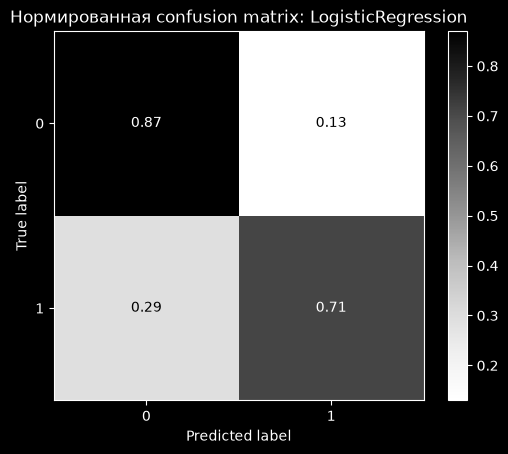

In [19]:
baseline.fit(X_train, y_train)

final_models = {
    "DummyClassifier": baseline,
    "SGDClassifier": sgd_search.best_estimator_,
    "LogisticRegression": logreg_search.best_estimator_,
}

test_results = pd.DataFrame([
    evaluate_classifier(name, model, X_test, y_test)
    for name, model in final_models.items()
])
display(test_results.round(4))

selected_name = candidate_comparison.iloc[0]["model"]
selected_model = final_models[selected_name]
selected_prediction = selected_model.predict(X_test)

print(classification_report(y_test, selected_prediction, zero_division=0))

ConfusionMatrixDisplay.from_estimator(
    selected_model, X_test, y_test,
    normalize="true", cmap="Greys",
)
plt.title(f"Нормированная confusion matrix: {selected_name}")
plt.show()

In [20]:
## 16. Анализ ошибок
error_table = X_test.copy()
error_table["true"] = np.asarray(y_test)
error_table["predicted"] = selected_prediction

selected_probabilities = selected_model.predict_proba(X_test)
error_table["confidence"] = selected_probabilities.max(axis=1)

errors = error_table[
    error_table["true"] != error_table["predicted"]
].sort_values("confidence", ascending=False)

display(errors.head(10))

,pclass,sex,age,sibsp,parch,fare,embarked,true,predicted,confidence
935,3,male,29.0,3,1,22.0250,S,1,0,0.953954
742,3,male,45.0,0,0,8.0500,S,1,0,0.937359
105,1,female,36.0,0,0,31.6792,C,0,1,0.931380
1120,3,male,25.0,1,0,7.7750,S,1,0,0.908387
926,3,male,NaN,0,0,7.7500,Q,1,0,0.904117
889,3,male,26.0,0,0,7.7750,S,1,0,0.882905
1254,3,male,25.0,0,0,0.0000,S,1,0,0.880201
693,3,male,21.0,0,0,7.8208,Q,1,0,0.879858
949,3,male,26.0,0,0,56.4958,S,1,0,0.876139
1121,3,male,NaN,1,1,22.3583,C,1,0,0.844302


In [21]:
## 17. Анализ коэффициентов
feature_names = selected_model.named_steps["prep"].get_feature_names_out()
model = selected_model.named_steps["model"]

class_index = 0
coefficients = model.coef_[class_index]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients),
}).sort_values("abs_coefficient", ascending=False)

display(coefficient_table.head(15))

,feature,coefficient,abs_coefficient
6,cat__sex_male,-1.296770,1.296770
5,cat__sex_female,1.184498,1.184498
0,num__pclass,-0.745176,0.745176
7,cat__embarked_C,0.469002,0.469002
1,num__age,-0.464082,0.464082
8,cat__embarked_Q,-0.366327,0.366327
2,num__sibsp,-0.312975,0.312975
9,cat__embarked_S,-0.214947,0.214947
4,num__fare,0.064068,0.064068
3,num__parch,0.007518,0.007518
